<a href="https://colab.research.google.com/github/SAfsana/COVID-19-EDA/blob/main/Internship_Data_Analysis_Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Internship Data Analysis – Model Comparison (Google Colab)

This notebook evaluates **four classification algorithms** using Accuracy, Precision, Recall and F1-score, then selects the best model using **weighted F1-score**.

Your screenshots show:
- **Customer dataset:** `shopping_data.csv` / `shopping_trends.csv` (3,900 rows, 19 columns).
- **Sales dataset:** `shopping_trends.csv` (same shopping-trends data shown in your second screenshot).
- **Website traffic dataset:** `traffic.csv` (226,278 rows, 9 columns).

**Important:** Customer and sales screenshots show the same dataset. The two analyses below use different prediction targets, but they are not two independent datasets. For sales, purchase amount is grouped into Low / Medium / High so that the requested classification metrics can be calculated. For a true numerical sales forecast, use MAE, RMSE and R² instead.

Run each section separately and upload the matching CSV when prompted. The scores are calculated from your uploaded data; they are not manually fixed.


In [1]:
# Common imports and reusable model-evaluation function
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

def clean_column_names(data):
    data = data.copy()
    data.columns = (data.columns.astype(str).str.strip()
                    .str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True)
                    .str.strip("_"))
    return data

def evaluate_classifiers(data, target, title, drop_columns=None, max_categories=100):
    data = clean_column_names(data)
    target = target.lower().replace(" ", "_")
    drop_columns = drop_columns or []

    if target not in data.columns:
        raise ValueError(
            f"Target column '{target}' not found. Available columns: {list(data.columns)}"
        )

    data = data.dropna(subset=[target]).copy()
    y_text = data[target].astype(str).str.strip()

    # Remove rows with blank target values
    valid = y_text.ne("") & y_text.ne("nan")
    data, y_text = data.loc[valid].copy(), y_text.loc[valid]

    # Combine very rare target labels to avoid unusably tiny classes
    counts = y_text.value_counts()
    rare_labels = counts[counts < 5].index
    if len(rare_labels):
        y_text = y_text.where(~y_text.isin(rare_labels), "Other")

    if y_text.nunique() < 2:
        raise ValueError(
            f"'{target}' has only one class after cleaning. Classification metrics "
            "cannot compare models. Choose a target column with at least two classes."
        )

    X = data.drop(columns=[target] + [c for c in drop_columns if c in data.columns],
                  errors="ignore")

    # Remove columns that are entirely empty and columns with only one value
    X = X.dropna(axis=1, how="all")
    X = X.loc[:, X.nunique(dropna=False) > 1]

    # Convert date-like columns into useful numeric parts
    for col in list(X.columns):
        if "date" in col or "time" in col:
            parsed = pd.to_datetime(X[col], errors="coerce")
            if parsed.notna().sum() > 0:
                X[col + "_year"] = parsed.dt.year
                X[col + "_month"] = parsed.dt.month
                X[col + "_day"] = parsed.dt.day
                X = X.drop(columns=[col])

    # Keep very high-cardinality text columns manageable
    for col in list(X.select_dtypes(include=["object", "category"]).columns):
        if X[col].nunique() > max_categories:
            X = X.drop(columns=[col])

    # Ensure remaining values are suitable for sklearn
    for col in X.select_dtypes(include=["object", "category"]).columns:
        X[col] = X[col].astype(str).replace({"nan": np.nan, "None": np.nan})

    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipe, numeric_cols),
        ("categorical", categorical_pipe, categorical_cols)
    ])

    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(y_text)

    # Stratify only when every class has at least two rows
    stratify_y = y if pd.Series(y).value_counts().min() >= 2 else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=stratify_y
    )

    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=12, min_samples_split=10, class_weight="balanced",
            random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=150, max_depth=15, min_samples_split=5,
            class_weight="balanced_subsample", random_state=42, n_jobs=-1
        ),
        "Extra Trees": ExtraTreesClassifier(
            n_estimators=150, max_depth=15, min_samples_split=5,
            class_weight="balanced", random_state=42, n_jobs=-1
        )
    }

    results = []
    fitted_models = {}

    for name, model in models.items():
        pipeline = Pipeline([
            ("preprocessing", preprocessor),
            ("classifier", model)
        ])
        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        results.append({
            "Algorithm": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
            "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
            "F1 Score": f1_score(y_test, predictions, average="weighted", zero_division=0)
        })
        fitted_models[name] = pipeline

    result_df = pd.DataFrame(results).sort_values(
        by="F1 Score", ascending=False
    ).reset_index(drop=True)

    print("\n", title)
    print("Target column:", target)
    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))
    print("Classes:", list(label_encoder.classes_))
    display(result_df.round(4))

    # Plot the four requested evaluation metrics
    metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
    result_df.set_index("Algorithm")[metrics].plot(
        kind="bar", figsize=(12, 6), ylim=(0, 1.05)
    )
    plt.title(title + " – Algorithm Evaluation")
    plt.ylabel("Score")
    plt.xlabel("Algorithm")
    plt.xticks(rotation=20, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    best_name = result_df.iloc[0]["Algorithm"]
    best_model = fitted_models[best_name]
    best_predictions = best_model.predict(X_test)

    print("\nBEST ALGORITHM:", best_name)
    print("Selected using the highest weighted F1-score.")
    print("\nClassification report for the best algorithm:")
    print(classification_report(
        y_test, best_predictions, target_names=label_encoder.classes_,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, best_predictions,
        display_labels=label_encoder.classes_,
        xticks_rotation=45, cmap="Blues"
    )
    plt.title(title + " – Best Model Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return result_df, best_model, label_encoder


## 1. Customer Analysis – Predict Subscription Status

Uses the shopping-trends dataset. The target is `Subscription Status` (Yes / No). Customer ID is excluded because it is only an identifier.

Saving shopping _data.csv to shopping _data.csv
Dataset shape: (3900, 19)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


Columns: ['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Payment Method', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Preferred Payment Method', 'Frequency of Purchases']

 Customer Analysis – Subscription Status
Target column: subscription_status
Training records: 3120
Testing records: 780
Classes: ['No', 'Yes']


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,1.0000,1.0000,1.0000,1.0000
1,Random Forest,1.0000,1.0000,1.0000,1.0000
2,Logistic Regression,0.9833,0.9837,0.9833,0.9834
3,Extra Trees,0.9321,0.9457,0.9321,0.9342


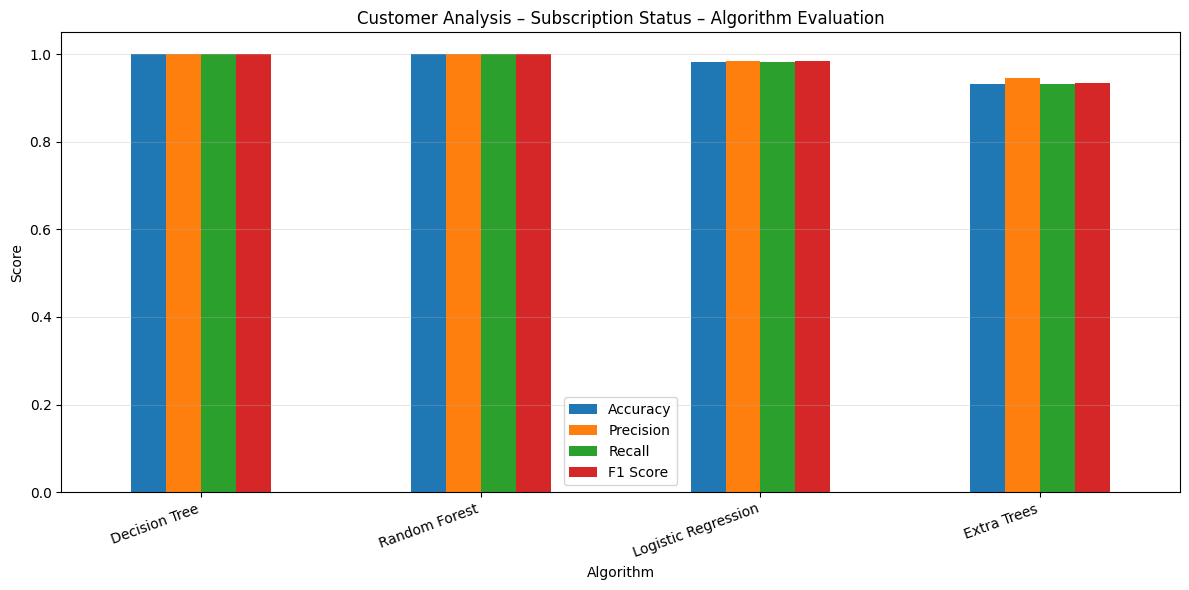


BEST ALGORITHM: Decision Tree
Selected using the highest weighted F1-score.

Classification report for the best algorithm:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00       569
         Yes       1.00      1.00      1.00       211

    accuracy                           1.00       780
   macro avg       1.00      1.00      1.00       780
weighted avg       1.00      1.00      1.00       780



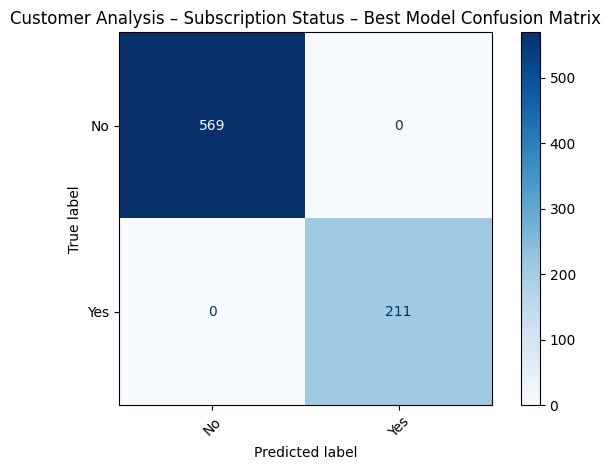

In [2]:
uploaded = files.upload()
customer_file = next(iter(uploaded))
customer_df = pd.read_csv(customer_file)

print("Dataset shape:", customer_df.shape)
display(customer_df.head())
print("Columns:", customer_df.columns.tolist())

customer_results, customer_best_model, customer_label_encoder = evaluate_classifiers(
    customer_df,
    target="Subscription Status",
    title="Customer Analysis – Subscription Status",
    drop_columns=["Customer ID"]
)


## 2. Sales Analysis – Classify Purchase Amount

Your screenshot shows the same `shopping_trends.csv` file used for Customer Analysis. Here, `Purchase Amount (USD)` is divided into three groups (Low, Medium and High) using the dataset's 33rd and 66th percentiles. This makes Accuracy, Precision, Recall and F1-score applicable.

If your faculty expects an actual numerical sales prediction, use regression metrics (MAE, RMSE and R²) instead of classification metrics.

Saving shopping_trends (1).csv to shopping_trends (1).csv
Purchase amount group counts:


,count
purchase_level,
Low,1300
Medium,1300
High,1300



 Sales Analysis – Purchase Amount Category
Target column: purchase_level
Training records: 3120
Testing records: 780
Classes: ['High', 'Low', 'Medium']


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Extra Trees,0.3487,0.3480,0.3487,0.3479
1,Logistic Regression,0.3423,0.3418,0.3423,0.3417
2,Random Forest,0.3269,0.3265,0.3269,0.3264
3,Decision Tree,0.3321,0.3232,0.3321,0.2933


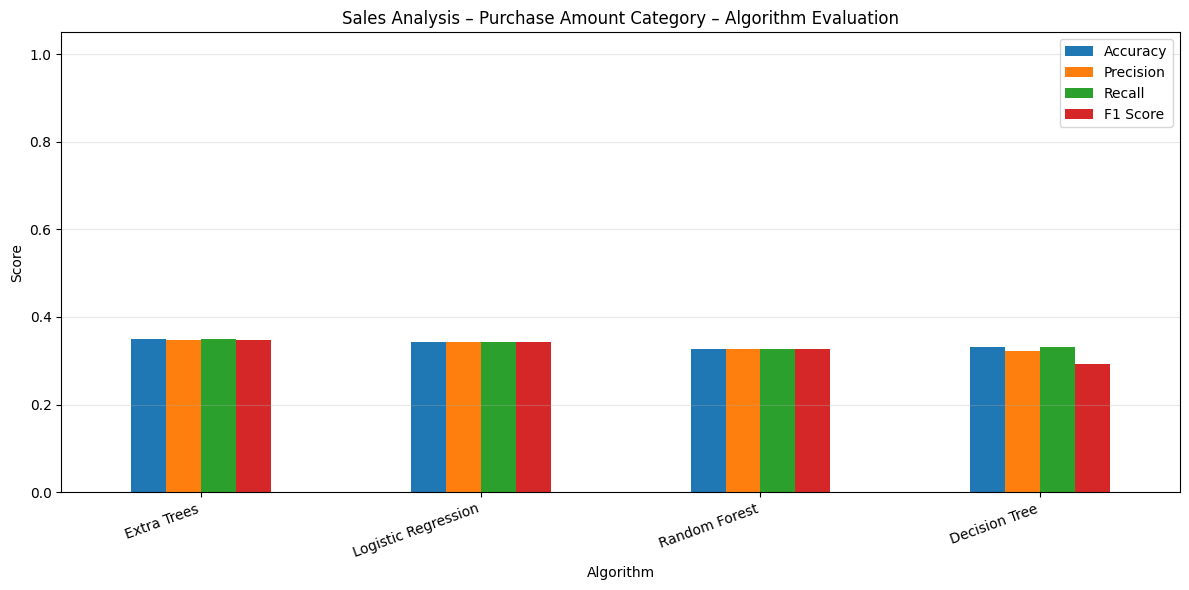


BEST ALGORITHM: Extra Trees
Selected using the highest weighted F1-score.

Classification report for the best algorithm:
              precision    recall  f1-score   support

        High       0.35      0.38      0.36       260
         Low       0.37      0.37      0.37       260
      Medium       0.32      0.30      0.31       260

    accuracy                           0.35       780
   macro avg       0.35      0.35      0.35       780
weighted avg       0.35      0.35      0.35       780



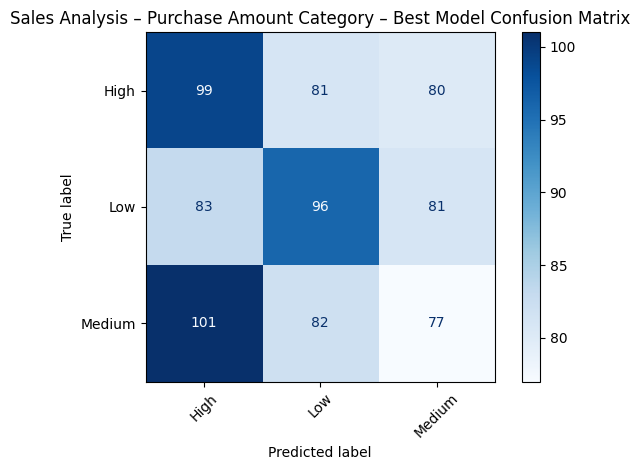

In [3]:
uploaded = files.upload()
sales_file = next(iter(uploaded))
sales_df = clean_column_names(pd.read_csv(sales_file))

amount_col = "purchase_amount_usd"
if amount_col not in sales_df.columns:
    raise ValueError(
        "Purchase amount column not found. Available columns: "
        + str(sales_df.columns.tolist())
    )

# Convert amount to numeric and remove rows where it is missing
sales_df[amount_col] = pd.to_numeric(sales_df[amount_col], errors="coerce")
sales_df = sales_df.dropna(subset=[amount_col]).copy()

# Create Low / Medium / High purchase amount classes
sales_df["purchase_level"] = pd.qcut(
    sales_df[amount_col].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

print("Purchase amount group counts:")
display(sales_df["purchase_level"].value_counts())

sales_results, sales_best_model, sales_label_encoder = evaluate_classifiers(
    sales_df,
    target="purchase_level",
    title="Sales Analysis – Purchase Amount Category",
    drop_columns=["customer_id", "purchase_amount_usd"]
)


## 3. Website Traffic Analysis – Predict Event Type

The traffic screenshot shows columns such as `event`, `date`, `country`, `city`, `artist`, `album`, `track`, `isrc` and `linkid`. The code first tries to predict `event`. If the file contains only one event class (for example, every row is `click`), it automatically switches to `country`, because a one-class target cannot be used to compare classifiers. Very high-cardinality identifiers and music-title columns are excluded to keep training practical.

Saving e-shop clothing 2008.csv.zip to e-shop clothing 2008.csv (1).zip
Dataset shape: (165474, 14)


,year,month,day,order,country,session_id,page_1_main_category,page_2_clothing_model,colour,location,model_photography,price,price_2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


Columns: ['year', 'month', 'day', 'order', 'country', 'session_id', 'page_1_main_category', 'page_2_clothing_model', 'colour', 'location', 'model_photography', 'price', 'price_2', 'page']
NOTICE: Event has only one class. Predicting country instead.

 Website Traffic Analysis – Country
Target column: country
Training records: 132379
Testing records: 33095
Classes: ['10', '11', '12', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '27', '28', '29', '3', '30', '31', '32', '34', '36', '37', '38', '39', '41', '42', '43', '44', '45', '46', '47', '6', '7', '9', 'Other']


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.6456,0.7773,0.6456,0.6963
1,Extra Trees,0.4587,0.7712,0.4587,0.5588
2,Decision Tree,0.1771,0.8339,0.1771,0.2562
3,Logistic Regression,0.0055,0.4452,0.0055,0.0042


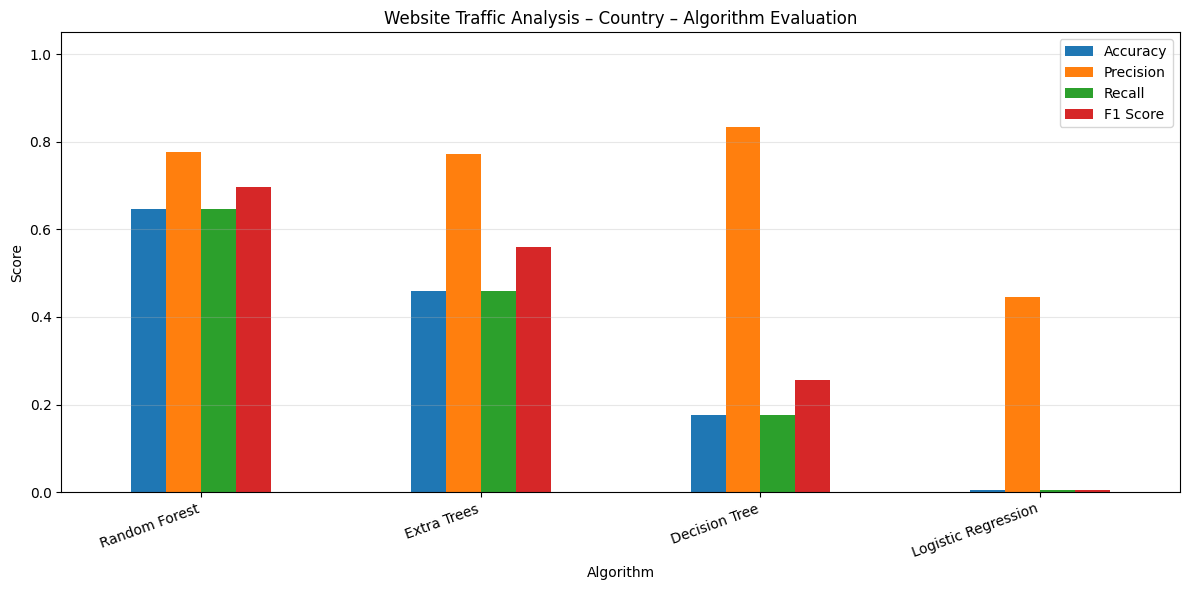


BEST ALGORITHM: Random Forest
Selected using the highest weighted F1-score.

Classification report for the best algorithm:
              precision    recall  f1-score   support

          10       0.06      0.27      0.10        30
          11       0.09      0.96      0.16        23
          12       0.17      0.57      0.26        42
          14       0.27      0.33      0.30         9
          15       0.05      0.36      0.09        25
          16       0.32      0.54      0.40       167
          17       0.22      0.40      0.29         5
          18       0.50      1.00      0.67         3
          19       0.57      0.67      0.62         6
           2       0.07      0.25      0.11        12
          20       1.00      1.00      1.00         2
          21       0.12      0.25      0.16       162
          22       0.09      0.59      0.15        29
          23       0.32      0.67      0.43         9
          24       0.25      0.41      0.31       818
          2

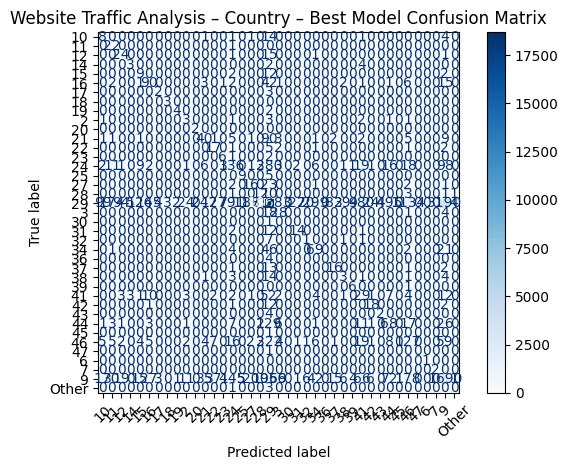

In [5]:
uploaded = files.upload()
traffic_file = next(iter(uploaded))
traffic_df = clean_column_names(pd.read_csv(traffic_file))

print("Dataset shape:", traffic_df.shape)
display(traffic_df.head())
print("Columns:", traffic_df.columns.tolist())

# Use event when it contains more than one class; otherwise use country
if "event" in traffic_df.columns and traffic_df["event"].nunique(dropna=True) >= 2:
    traffic_target = "event"
elif "country" in traffic_df.columns and traffic_df["country"].nunique(dropna=True) >= 2:
    traffic_target = "country"
    print("NOTICE: Event has only one class. Predicting country instead.")
else:
    raise ValueError(
        "Neither event nor country has at least two classes. "
        "Choose another target column with multiple categories."
    )

traffic_results, traffic_best_model, traffic_label_encoder = evaluate_classifiers(
    traffic_df,
    target=traffic_target,
    title="Website Traffic Analysis – " + traffic_target.title(),
    drop_columns=["linkid", "isrc", "artist", "album", "track", "city"],
    max_categories=100
)


## Final comparison and conclusion

Run this cell after completing all three sections. It prints the best algorithm for each analysis. The best model is chosen from the test-set results using the highest **weighted F1-score**; the scores are computed from the real uploaded data.

**Presentation note:** Do not claim an algorithm is best before running the notebook. Report the algorithm name and values that appear in your own output.

In [6]:
summary = pd.DataFrame([
    {
        "Case Study": "Customer Analysis",
        "Best Algorithm": customer_results.iloc[0]["Algorithm"],
        "Accuracy": customer_results.iloc[0]["Accuracy"],
        "Precision": customer_results.iloc[0]["Precision"],
        "Recall": customer_results.iloc[0]["Recall"],
        "F1 Score": customer_results.iloc[0]["F1 Score"]
    },
    {
        "Case Study": "Sales Analysis",
        "Best Algorithm": sales_results.iloc[0]["Algorithm"],
        "Accuracy": sales_results.iloc[0]["Accuracy"],
        "Precision": sales_results.iloc[0]["Precision"],
        "Recall": sales_results.iloc[0]["Recall"],
        "F1 Score": sales_results.iloc[0]["F1 Score"]
    },
    {
        "Case Study": "Website Traffic Analysis",
        "Best Algorithm": traffic_results.iloc[0]["Algorithm"],
        "Accuracy": traffic_results.iloc[0]["Accuracy"],
        "Precision": traffic_results.iloc[0]["Precision"],
        "Recall": traffic_results.iloc[0]["Recall"],
        "F1 Score": traffic_results.iloc[0]["F1 Score"]
    }
])
display(summary.round(4))


,Case Study,Best Algorithm,Accuracy,Precision,Recall,F1 Score
0,Customer Analysis,Decision Tree,1.0000,1.0000,1.0000,1.0000
1,Sales Analysis,Extra Trees,0.3487,0.3480,0.3487,0.3479
2,Website Traffic Analysis,Random Forest,0.6456,0.7773,0.6456,0.6963
